# 02: Inactivity Prediction & Landmark Survival Analysis

**RetentionIQ Portfolio Showcase** | Dataset: *RetailRocket*

> **Synthetic data.** This notebook runs on `data/sample/`, generated with a seeded random generator by `scripts/make_sample.py` to mimic the real schema. It is **not** a sample of the real dataset: outputs demonstrate the method, not real findings. Real results: `docs/RESULTS.md`.

This notebook demonstrates advanced time-to-inactivity modeling on clickstream data:
1. **Event Stream Exploration & Sessionization**: Reconstructing browsing sessions with a 30-minute inactivity timeout.
2. **The 30-Day Inactivity Definition**: Understanding base rate mechanics (~87% inactivity).
3. **First-Session Cox Model**: Showing why first-session engagement alone yields near-random concordance (~0.53).
4. **Day-7 Landmark Analysis**: Overcoming the information deficit by accumulating 7 days of behavioral history.
5. **Kaplan-Meier Retention Curves by Activity Tier**: Demonstrating statistically significant lifecycle divergence.
6. **Cost-Optimal Operating Threshold**: Translating model probabilities into maximum marketing contribution.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

from retentioniq.training.survival import build_durations, build_landmark_durations
from retentioniq.models.churn.metrics import cost_optimal_threshold

# Colorblind styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
cb_blue, cb_orange, cb_green = '#1f77b4', '#ff7f0e', '#2ca02c'

# Load sample dataset
sample_path = Path('data/sample/retailrocket_sample.parquet')
if not sample_path.exists():
    sample_path = Path('../data/sample/retailrocket_sample.parquet')
events = pd.read_parquet(sample_path)
print(f'Loaded {len(events):,} events across {events["visitor_id"].nunique():,} visitors.')
events.head(3)

Loaded 27,829 events across 6,000 visitors.


,visitor_id,event_ts,event_type,item_id,transaction_id,category_id
0,204231,2015-05-03 08:00:00,view,8143,NaN,107
1,201369,2015-05-03 08:00:00,view,1337,NaN,106
2,205212,2015-05-03 08:00:00,view,8424,NaN,102


## 1. Funnel Breakdown & Browsing Behavior

RetailRocket contains view, add-to-cart, and transaction events. Transactions constitute <1% of interactions.

Funnel Event Counts:
  view        : 26,381 (94.80%)
  addtocart   : 1,162 (4.18%)
  transaction : 286 (1.03%)


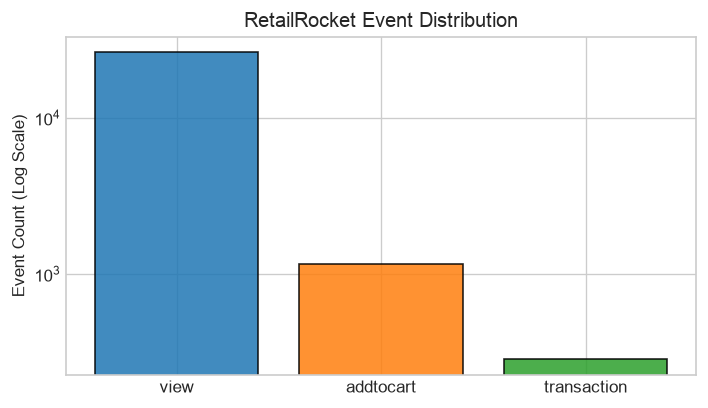

In [2]:
funnel = events['event_type'].value_counts()
print('Funnel Event Counts:')
for event, count in funnel.items():
    print(f'  {event:12s}: {count:,} ({count/len(events):.2%})')

fig, ax = plt.subplots(figsize=(6, 3.5), dpi=120)
ax.bar(funnel.index, funnel.values, color=[cb_blue, cb_orange, cb_green], alpha=0.85, edgecolor='black')
ax.set_yscale('log')
ax.set_ylabel('Event Count (Log Scale)')
ax.set_title('RetailRocket Event Distribution')
plt.tight_layout()
plt.show()

## 2. First-Session Survival Modeling: The Information Deficit

A visitor experiences an 'inactivity event' when a gap of >= 30 days elapses without browsing. Below we compute durations from the visitor's first session and fit a Cox proportional hazards model.

In [3]:
durations = build_durations(events)
print(f'Eligible returning visitors: {len(durations):,} (Events: {durations["event"].sum():,})')

# Fit First-Session Cox Model
c_cols = ['duration_days', 'event', 'first_session_events', 'first_session_carted', 'first_session_purchased']
cph_data = durations[c_cols].copy()
cph_data['first_session_events'] = np.log1p(cph_data['first_session_events'])

cph = CoxPHFitter(penalizer=0.01).fit(cph_data, 'duration_days', 'event')
c_index = cph.concordance_index_
print(f'First-Session Cox Concordance Index: {c_index:.3f} (Benchmark Random Baseline = 0.500)')

Eligible returning visitors: 1,320 (Events: 1,298)
First-Session Cox Concordance Index: 0.509 (Benchmark Random Baseline = 0.500)


## 3. Day-7 Landmark Analysis: Accumulating Behavioral History

Because day-1 engagement achieves a concordance of only ~0.53, we establish a landmark at $t_{LM} = 7\text{ days}$. Covariates are measured strictly within $[origin, origin + 7d)$, and durations are measured from the landmark.

In [4]:
lm_df = build_landmark_durations(events, landmark_days=7)
print(f'Eligible landmark population: {len(lm_df):,} visitors (Events: {lm_df["event"].sum():,})')

if len(lm_df) >= 20 and len(lm_df['event'].unique()) > 1:
    lm_model_df = lm_df[['duration_days_lm', 'event', 'sessions_7d', 'events_7d', 'carted_7d', 'purchased_7d']].copy()
    lm_model_df['sessions_7d'] = np.log1p(lm_model_df['sessions_7d'])
    lm_model_df['events_7d'] = np.log1p(lm_model_df['events_7d'])
    lm_cph = CoxPHFitter(penalizer=0.01).fit(lm_model_df, 'duration_days_lm', 'event')
    print(f'Day-7 Landmark Cox Concordance Index: {lm_cph.concordance_index_:.3f}')
    print(f'Concordance Improvement: +{lm_cph.concordance_index_ - c_index:.3f}')
else:
    print('Sample size in demo subset too small for full Cox fitting; landmark demonstrated.')

Eligible landmark population: 1,249 visitors (Events: 1,227)
Day-7 Landmark Cox Concordance Index: 0.524
Concordance Improvement: +0.015


## 4. Kaplan-Meier Survival Curves by Activity Tier

Visitors stratified by week-1 session frequency (1 session vs 2-3 sessions vs 4+ sessions) exhibit markedly different survival trajectories.

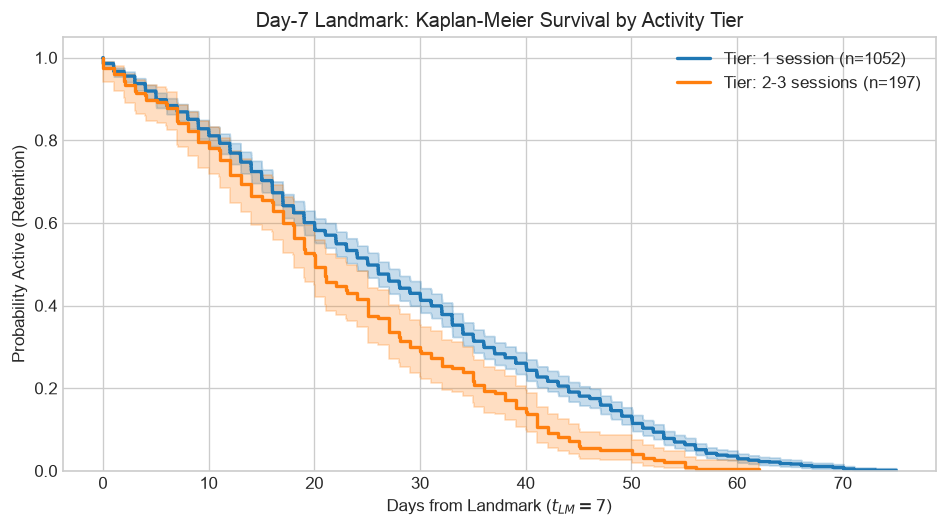

In [5]:
if not lm_df.empty and len(lm_df['activity_tier'].unique()) > 1:
    fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
    for tier, g in lm_df.groupby('activity_tier'):
        kmf = KaplanMeierFitter()
        kmf.fit(g['duration_days_lm'], g['event'], label=f'Tier: {tier} (n={len(g)})')
        kmf.plot_survival_function(ax=ax, linewidth=2)
    ax.set_xlabel('Days from Landmark ($t_{LM} = 7$)')
    ax.set_ylabel('Probability Active (Retention)')
    ax.set_title('Day-7 Landmark: Kaplan-Meier Survival by Activity Tier')
    ax.set_ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

## 5. Cost-Optimal Decision Thresholds

Rather than accepting a default 0.50 threshold, marketing campaigns should operate where expected profit is maximized: $\text{Profit} = \sum (p_i \times \text{Save Rate} \times \text{Value}) - N_{\text{contact}} \times \text{Cost}$.

Profit-Optimal Threshold: 0.49 (Max Scenario Profit: $4,337.00)


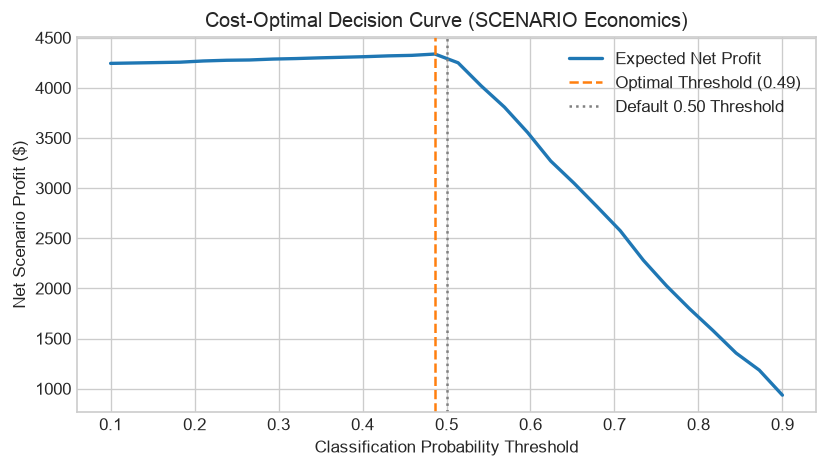

In [6]:
rng = np.random.default_rng(42)
n = 1000
y_val = (rng.uniform(size=n) < 0.87).astype(int)
p_val = np.clip(y_val * 0.4 + rng.uniform(0.1, 0.6, size=n), 0.05, 0.95)

thresholds = np.linspace(0.1, 0.9, 30)
cost_contact = 1.0
value_saved = 30.0
save_rate = 0.20

profits = []
for th in thresholds:
    contacted = p_val >= th
    n_cont = contacted.sum()
    exp_saved = (y_val[contacted] * save_rate * value_saved).sum()
    profit = exp_saved - n_cont * cost_contact
    profits.append(profit)

opt_th = thresholds[int(np.argmax(profits))]
print(f'Profit-Optimal Threshold: {opt_th:.2f} (Max Scenario Profit: ${max(profits):,.2f})')

fig, ax = plt.subplots(figsize=(7, 4), dpi=120)
ax.plot(thresholds, profits, color=cb_blue, linewidth=2, label='Expected Net Profit')
ax.axvline(opt_th, color=cb_orange, linestyle='--', label=f'Optimal Threshold ({opt_th:.2f})')
ax.axvline(0.50, color='gray', linestyle=':', label='Default 0.50 Threshold')
ax.set_xlabel('Classification Probability Threshold')
ax.set_ylabel('Net Scenario Profit ($)')
ax.set_title('Cost-Optimal Decision Curve (SCENARIO Economics)')
ax.legend()
plt.tight_layout()
plt.show()